# Synthetic Medical Data Generator

**VAE, DP-VAE and GANs for privacy-preserving healthcare research**

A complete, runnable study: generate synthetic patient records that preserve the
statistics of real clinical data, then *measure* fidelity, utility and privacy
rather than assert them.

| Family | What we measure | Key number |
|---|---|---|
| A. Fidelity | per-column KS, total-variation, Spearman correlation gap, PCA overlay, histograms, correlation heatmaps | correlation gap vs a naive baseline |
| B. Utility | TSTR (train synthetic, test real) vs the TRTR ceiling, Logistic Regression + Random Forest | accuracy / F1 / AUC |
| C. Privacy | exact-copy rate, distance-to-closest-record, distance-based membership-inference AUC, privacy-vs-utility curve over epsilon | attack AUC near 0.5 at small epsilon |

**Data protocol - the part to be able to defend.** Generators are fit on the
**train** split only (60%). Hyper-parameters are chosen on the **validation**
split only (20%). The **test** split (20%) is read once, at the end, for the
headline numbers, and it never influences training or model selection. The split
is stratified on the diagnosis and fixed at seed 42, so every run here uses
identical folds.

---
## 0. Setup

In [1]:
# Install what the study needs. On Colab this takes about a minute.
# ctgan gives us CTGAN + TVAE; opacus gives us differentially-private SGD.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu
%pip install -q opacus ctgan scikit-learn scipy matplotlib pandas numpy

import os, sys, warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, torch
print('torch', torch.__version__, '| cuda', torch.cuda.is_available())
print('device: everything below runs on CPU')
from synth.metrics import fidelity_report, utility_report, privacy_report
pd.set_option('display.width', 200)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Rangu Suchandra\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Rangu Suchandra\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


torch 2.10.0+cpu | cuda False
device: everything below runs on CPU


### Getting the `synth` package onto Colab

The notebook is a *driver*: it imports the same `synth/` library that
`run_pipeline.py`, `make_figures.py` and `app.py` use, so the notebook can never
report numbers that differ from the code. Choose one:

1. **Run locally** - put this `.ipynb` next to the `synth/` folder and skip this
   cell.
2. **Colab, upload** - run `python make_dist.py` in the project, then upload
   `synthetic_medical_data.zip` via the Colab files panel and run the cell.
3. **Colab, Drive** - put the zip in Google Drive and run the cell; it searches
   `/content/drive/MyDrive` too.

In [2]:
sys.path.insert(0, os.getcwd())
try:
    import synth
    print('found the synth package at', os.path.dirname(synth.__file__))
except Exception:
    import glob, zipfile
    cands = glob.glob(os.path.join(os.getcwd(), '*.zip')) + \
            glob.glob('/content/drive/MyDrive/*.zip')
    zips = [p for p in cands if 'medical' in p.lower() or 'synth' in p.lower()]
    assert zips, ('Upload synthetic_medical_data.zip, or place this notebook '
                  'next to the synth/ folder.')
    with zipfile.ZipFile(zips[0]) as zf:
        zf.extractall(os.getcwd())
    import synth
    print('unpacked', zips[0])

found the synth package at C:\Users\Rangu Suchandra\Desktop\GEN_AI\synth


## 1. Data

Two public UCI tables, deliberately different in size so the effect of sample
size on synthetic-data quality is visible rather than asserted:

- **Heart Disease, Cleveland** - 303 patients, 5 numeric + 8 categorical features
  + diagnosis. Small, and the hard case.
- **Pima Indians Diabetes** - 768 patients, 8 numeric + 1 derived categorical +
  outcome. Larger, same machinery.

Cleaning decisions, all taken from the **train** split so nothing leaks:

- Cleveland `?` markers (4 in `ca`, 2 in `thal`) are imputed with the train mode;
  all 303 rows are kept.
- Pima uses `0` as a missing marker for glucose / blood pressure / skin thickness
  / insulin / BMI, because a living person has none of those values of zero. They
  become NaN and are imputed from the train median. `pregnancies == 0` is real and
  is left alone.
- Cleveland `num` (0-4, count of stenotic vessels) is binarised to `target`,
  following the UCI data description's own recommendation.
- A `bmi_class` column (WHO cut-points) is added to Pima so the mixed-type
  machinery is exercised on both datasets. Stated as a design choice, not hidden.

In [3]:
from synth.data import load_dataset

ds = load_dataset('heart')
print('splits  ', ds.sizes)
print('handled ', ds.missing_counts)
print('numeric ', [c.name for c in ds.schema.numeric])
print('categor ', {c.name: c.categories for c in ds.schema.categorical})
print('label   ', ds.schema.label, '=', ds.schema.label_name)
print('positive defined as:', ds.schema.positive_is)
ds.train.head(6)

splits   {'train': 181, 'val': 61, 'test': 61}
handled  {'ca': 4, 'thal': 2, 'dropped_exact_duplicates': 0}
numeric  ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categor  {'sex': [0, 1], 'cp': [1, 2, 3, 4], 'fbs': [0, 1], 'restecg': [0, 1, 2], 'exang': [0, 1], 'slope': [1, 2, 3], 'ca': [0, 1, 2, 3], 'thal': [3, 6, 7]}
label    target = coronary artery disease
positive defined as: num > 0 (any stenosis detected)


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
0,62.0,120.0,267.0,99.0,1.8,1,4,0,0,1,2,2,7,1
1,59.0,150.0,212.0,157.0,1.6,1,3,1,0,0,1,0,3,0
2,57.0,150.0,276.0,112.0,0.6,1,4,0,2,1,2,1,6,1
3,44.0,120.0,263.0,173.0,0.0,1,2,0,0,0,1,0,7,0
4,59.0,140.0,177.0,162.0,0.0,1,4,0,0,1,1,1,7,1
5,57.0,110.0,201.0,126.0,1.5,1,4,0,0,1,2,0,6,0


In [4]:
# Check the protocol held: prevalence identical in all three folds, and no
# missing values left anywhere.
for name, part in [('train', ds.train), ('val', ds.val), ('test', ds.test)]:
    print(f'{name:6s} n={len(part):4d}  disease_rate={part.target.mean():.4f}  '
          f'nan={int(part.isna().any().any())}')
assert not ds.train.isna().any().any() and not ds.test.isna().any().any()
print('OK - no missing values remain, folds are balanced')

train  n= 181  disease_rate=0.4586  nan=0
val    n=  61  disease_rate=0.4590  nan=0
test   n=  61  disease_rate=0.4590  nan=0
OK - no missing values remain, folds are balanced


## 2. Encoding

Mixed-type tables need an explicit encoding before any network can touch them.
We use **mode-based** encoding: min-max (through a train-fitted rank transform)
for numerics, one-hot for categoricals.

Two things worth knowing, because they are the two commonest ways this goes
wrong:

1. Categoricals are **not** label-encoded. `thal` takes values {3, 6, 7} meaning
   normal / fixed defect / reversible defect - 6 is not "twice as normal as 3",
   and an integer encoding would invent that ordering.
2. The numeric transform is a rank-to-Gaussian map fitted on the train split.
   Plain min-max left the 28.7% exact-0.0 atom in `oldpeak` unreproducible by a
   mean-output decoder (measured KS 0.43). The rank transform has flat inverse
   regions, which re-creates the atom.

**Consequence that must be stated in the report:** because the transform is
fitted on the training marginal, 1-D marginals are partly guaranteed by
construction, so KS and TV are *not* the metrics that distinguish these models.
The joint metrics - correlation gap and TSTR - are. (The naive baseline also
matches marginals exactly, so the comparison stays fair.)

In [5]:
from synth.encoding import TabularEncoder
from synth.models import EncodedTable

enc = TabularEncoder(ds.schema)
X = enc.encode(ds.train)
print('encoded shape', X.shape, '-> dim =', enc.dim)
print('all values in [0,1]:', X.min() >= 0 and X.max() <= 1)
print()
for slot in enc.slots:
    print(f'  {slot.name:20s} {slot.kind:12s} cols {slot.start}:{slot.stop}')

encoded shape (181, 30) -> dim = 30
all values in [0,1]: True

  age                  numeric      cols 0:1
  trestbps             numeric      cols 1:2
  chol                 numeric      cols 2:3
  thalach              numeric      cols 3:4
  oldpeak              numeric      cols 4:5
  sex                  categorical  cols 5:7
  cp                   categorical  cols 7:11
  fbs                  categorical  cols 11:13
  restecg              categorical  cols 13:16
  exang                categorical  cols 16:18
  slope                categorical  cols 18:21
  ca                   categorical  cols 21:25
  thal                 categorical  cols 25:28
  target               categorical  cols 28:30


### The loss-imbalance problem - read this, it is the interesting bug

The specification asks for MSE on numerics and cross-entropy per categorical
column. Averaged MSE on `[0,1]` numerics is ~0.028 at a constant predictor while
averaged cross-entropy on categoricals is ~0.98 nats. Left unweighted the
categorical term is **35x larger**, the optimiser spends all its capacity on the
categorical columns, and the numeric columns are never modelled at all.

That is what a silently broken tabular VAE looks like. It is also why the first
version of this study had a VAE whose correlation gap was *worse than the naive
baseline*: the metric was telling the truth about a loss that was ignoring half
the data.

In [6]:
import torch
import torch.nn.functional as Fn

et = EncodedTable(ds.train, ds.schema)
num = torch.tensor(et.num)
cat = torch.tensor(et.cat)
mean_pred = torch.tensor(num.mean(axis=0)).expand_as(num)
zero_logits = [torch.zeros(len(num), w) for w in et.widths]
mse = Fn.mse_loss(mean_pred, num, reduction='none').mean(1).mean().item()
ce = torch.stack([Fn.cross_entropy(zero_logits[j], cat[:, j], reduction='none')
                  for j in range(len(et.widths))], 1).mean(1).mean().item()
print('numeric MSE term   %.5f' % mse)
print('categorical CE term  %.5f' % ce)
print('imbalance ratio      %.1fx  -> the numeric columns would be ignored'
      % (ce / mse))

numeric MSE term   0.03885
categorical CE term  0.98234
imbalance ratio      25.3x  -> the numeric columns would be ignored


## 3. The five generators

All of them share one interface - `fit(train_df, val_df=val_df)` then
`sample(n, diversity=..., seed=...)` - so nothing downstream special-cases a
model.

| Label | Model | Role in the study |
|---|---|---|
| `naive` | independent per-column resampling | the control: matches every marginal by construction, destroys every association |
| `vae` | custom VAE: (mu, logvar) -> reparameterisation -> split heads, KL annealing | the main model |
| `dp_vae` | the same VAE under Opacus DP-SGD, epsilon 1 / 3 / 10 / 30 | the privacy experiment |
| `ctgan`, `tvae` | the `ctgan` package | published reference points |
| `wgan_gp` | WGAN-GP on the *same* encoded space as the VAE | the extra; makes VAE-vs-GAN an architecture comparison, not a preprocessing one |

In [7]:
from synth.models import build_model, diversity_to_knobs

EPOCHS = 150          # keeps the notebook quick; run_pipeline.py uses 400
CFG = {
    'naive':   {},
    'vae':     dict(w_num=120.0, beta_max=0.1, latent_dim=16, epochs=EPOCHS),
    'dp_vae':  dict(w_num=120.0, beta_max=0.1, latent_dim=16, epochs=EPOCHS,
                    epsilon=10.0, max_grad_norm=1.0),
    'ctgan':   dict(epochs=60, batch_size=100, embedding_dim=32, dim=(128, 128)),
    'tvae':    dict(epochs=60, batch_size=100, embedding_dim=32, dim=(128, 128)),
    'wgan_gp': dict(epochs=600, batch_size=32, z_dim=16, hidden=(128, 64)),
}

models, samples = {}, {}
for name, hp in CFG.items():
    t0 = time.time()
    m = build_model(name, ds.schema, seed=0, **hp)
    m.fit(ds.train, val_df=ds.val)
    models[name] = m
    samples[name] = m.sample(1000, seed=0)
    priv = getattr(m, 'privacy_note', 'non-private')
    print('%-8s fit %6.1fs  rows=%d  privacy=%s' % (name, m.fit_seconds,
                                                    len(samples[name]), priv))
samples['vae'].head(5)

naive    fit    0.0s  rows=1000  privacy=non-private


vae      fit   10.6s  rows=1000  privacy=non-private


W1025 07:38:21.792000 35696 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


10/25/2026 07:38:28:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.


dp_vae   fit   24.3s  rows=1000  privacy=target_eps=10, sigma=2.1082, clip=1, exp_batch=36, delta=5.52e-03


ctgan    fit    5.2s  rows=1000  privacy=non-private


tvae     fit    2.0s  rows=1000  privacy=non-private


wgan_gp  fit   10.2s  rows=1000  privacy=non-private


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
0,46,140,233,144,0.6,1,4,0,2,1,2,0,3,1
1,65,152,250,163,0.0,1,4,1,0,0,1,1,3,0
2,47,107,276,130,1.4,1,4,0,0,1,2,0,7,0
3,56,110,240,113,1.0,1,1,0,0,0,3,0,7,0
4,58,144,233,158,0.6,1,3,0,0,0,2,0,3,0


In [8]:
# Every generated record must be a legal patient. This is measured, not assumed:
# it would fail loudly if the sanitiser were bypassed - e.g. a CTGAN that emitted
# an age of -4, or a thal of 5 (a level that does not exist in the real cohort).
from synth.metrics import validity_rate

for name, syn in samples.items():
    r = validity_rate(syn, ds.schema)
    assert r == 1.0, '%s emitted illegal values (%.4f)' % (name, r)
    print('%-8s valid_rate=%.4f  age=%d-%d  thal=%s  oldpeak_decimals_ok=%s' % (
        name, r, int(syn.age.min()), int(syn.age.max()),
        sorted(int(v) for v in syn.thal.unique()),
        bool(np.allclose(syn.oldpeak, syn.oldpeak.round(1)))))

naive    valid_rate=1.0000  age=30-75  thal=[3, 6, 7]  oldpeak_decimals_ok=True
vae      valid_rate=1.0000  age=30-71  thal=[3, 6, 7]  oldpeak_decimals_ok=True
dp_vae   valid_rate=1.0000  age=31-72  thal=[3, 6, 7]  oldpeak_decimals_ok=True
ctgan    valid_rate=1.0000  age=27-80  thal=[3, 6, 7]  oldpeak_decimals_ok=True
tvae     valid_rate=1.0000  age=32-73  thal=[3, 7]  oldpeak_decimals_ok=True
wgan_gp  valid_rate=1.0000  age=43-57  thal=[3, 6, 7]  oldpeak_decimals_ok=True


### What the diversity knob actually does

One slider drives two mechanisms, and 0.5 is the neutral point that reproduces
the published settings exactly. Lowering it sharpens categorical sampling and
tightens the latent draw; raising it flattens both. For CTGAN/TVAE the package
exposes no per-row probabilities, so there `diversity` becomes post-hoc kernel
jitter on the numeric columns - a different mechanism, and labelled as such in
the demo.

In [9]:
for d in [0.0, 0.5, 1.0]:
    T, L = diversity_to_knobs(d)
    syn = models['vae'].sample(600, diversity=d, seed=1)
    top = syn.cp.value_counts(normalize=True).iloc[0]
    rare = syn.thal.value_counts(normalize=True).min()
    print('diversity=%.1f -> temperature=%.2f latent_scale=%.2f | '
          'most common cp share=%.3f | rarest thal share=%.3f | unique rows=%d'
          % (d, T, L, top, rare, syn.drop_duplicates().shape[0]))
print()
print('higher diversity = flatter categorical sampling = rarer levels appear more, '
      'and more duplicate-free rows')

diversity=0.0 -> temperature=0.71 latent_scale=0.75 | most common cp share=0.517 | rarest thal share=0.032 | unique rows=600
diversity=0.5 -> temperature=1.00 latent_scale=1.00 | most common cp share=0.463 | rarest thal share=0.060 | unique rows=600
diversity=1.0 -> temperature=1.41 latent_scale=1.25 | most common cp share=0.427 | rarest thal share=0.082 | unique rows=600

higher diversity = flatter categorical sampling = rarer levels appear more, and more duplicate-free rows


## 4. Evaluation A - fidelity

Everything here is measured against the **held-out test split**. Measuring
against the training split would flatter every model, because a generator that
simply memorised its input scores perfectly on it - that is a privacy failure
being reported as a fidelity success.

The **noise floor** is the most important number on this page: it is the score
you get by comparing the *real* training split to the *real* test split with the
identical metric code. With only 61 held-out patients the floor sits near 0.11,
so "the gap is 0.13" is meaningless on its own. What is meaningful is that the
naive baseline is near 0.21 and the VAE is near 0.13.

In [10]:
from synth.metrics import ks_per_column, tv_per_column, spearman_gap

floor = fidelity_report(ds.train, ds.test, ds.schema, per_column=False)
fk, ft, fg = floor['fid_ks_mean'], floor['fid_tv_mean'], floor['fid_spearman_gap']
print('NOISE FLOOR (real train vs real test):  KS=%.4f  TV=%.4f  gap=%.4f'
      % (fk, ft, fg))
print()

fid_rows = []
for name, syn in samples.items():
    f = fidelity_report(syn, ds.test, ds.schema, per_column=False)
    fid_rows.append(dict(model=name, ks=f['fid_ks_mean'], tv=f['fid_tv_mean'],
                         gap=f['fid_spearman_gap'],
                         gap_vs_floor=f['fid_spearman_gap'] / fg,
                         worst_pair_gap=f['fid_spearman_gap_max'],
                         valid=f['fid_valid_rate']))
fid = pd.DataFrame(fid_rows).sort_values('gap').reset_index(drop=True)
fid

NOISE FLOOR (real train vs real test):  KS=0.1283  TV=0.0397  gap=0.0993



,model,ks,tv,gap,gap_vs_floor,worst_pair_gap,valid
0,vae,0.162889,0.045898,0.138107,1.390356,0.553205,1.0
1,naive,0.138485,0.039361,0.181358,1.825774,0.596016,1.0
2,tvae,0.250485,0.249871,0.183934,1.851711,0.852301,1.0
3,dp_vae,0.111993,0.189514,0.185418,1.866648,0.603430,1.0
4,ctgan,0.288420,0.046508,0.191848,1.931382,0.574553,1.0
5,wgan_gp,0.599593,0.239381,0.194140,1.954453,0.834961,1.0


**Acceptance criterion 1: the VAE correlation gap must be clearly below the naive
baseline.** The naive resampler samples each column *independently*, so it cannot
represent any association at all - its gap is essentially the mean absolute
correlation of the real data.

In [11]:
nv = float(fid.loc[fid.model == 'naive', 'gap'].iloc[0])
va = float(fid.loc[fid.model == 'vae', 'gap'].iloc[0])
print('naive gap %.4f  ->  VAE gap %.4f   (%.1f%% reduction)   %s'
      % (nv, va, 100 * (1 - va / nv), 'PASS' if va < nv else 'FAIL'))
assert va < nv, 'the VAE must at least beat the naive baseline on joint structure'

naive gap 0.1814  ->  VAE gap 0.1381   (23.8% reduction)   PASS


In [12]:
# Which specific association broke, per model - the detail behind the mean.
ks = pd.DataFrame({m: ks_per_column(samples[m], ds.test, ds.schema).set_index('column').ks_stat
                   for m in samples})
ks['noise floor'] = ks_per_column(ds.train, ds.test, ds.schema).set_index('column').ks_stat
tv = pd.DataFrame({m: tv_per_column(samples[m], ds.test, ds.schema).set_index('column').tv
                   for m in samples})
tv['noise floor'] = tv_per_column(ds.train, ds.test, ds.schema).set_index('column').tv
print('per-column KS (numeric)'); print(ks.round(4).to_string())
print(); print('per-column total variation (categorical + label)')
print(tv.round(4).to_string())

per-column KS (numeric)
           naive     vae  dp_vae   ctgan    tvae  wgan_gp  noise floor
column                                                                
age       0.1349  0.1124  0.1049  0.1009  0.2677   0.4808       0.0898
trestbps  0.1418  0.1399  0.1499  0.4976  0.3353   0.3722       0.1497
chol      0.1890  0.2200  0.1640  0.1942  0.2766   0.9100       0.1810
thalach   0.0613  0.1223  0.0583  0.4051  0.0923   0.5956       0.0698
oldpeak   0.1655  0.2199  0.0830  0.2443  0.2805   0.6393       0.1513

per-column total variation (categorical + label)
          naive     vae  dp_vae   ctgan    tvae  wgan_gp  noise floor
column                                                               
sex      0.0151  0.0411  0.1061  0.0249  0.3279   0.2829       0.0202
cp       0.0528  0.0228  0.2903  0.0807  0.4964   0.1357       0.0513
fbs      0.0091  0.0311  0.2951  0.0291  0.1639   0.1639       0.0073
restecg  0.0402  0.0840  0.2288  0.0688  0.0630   0.3192       0.0493
exang    

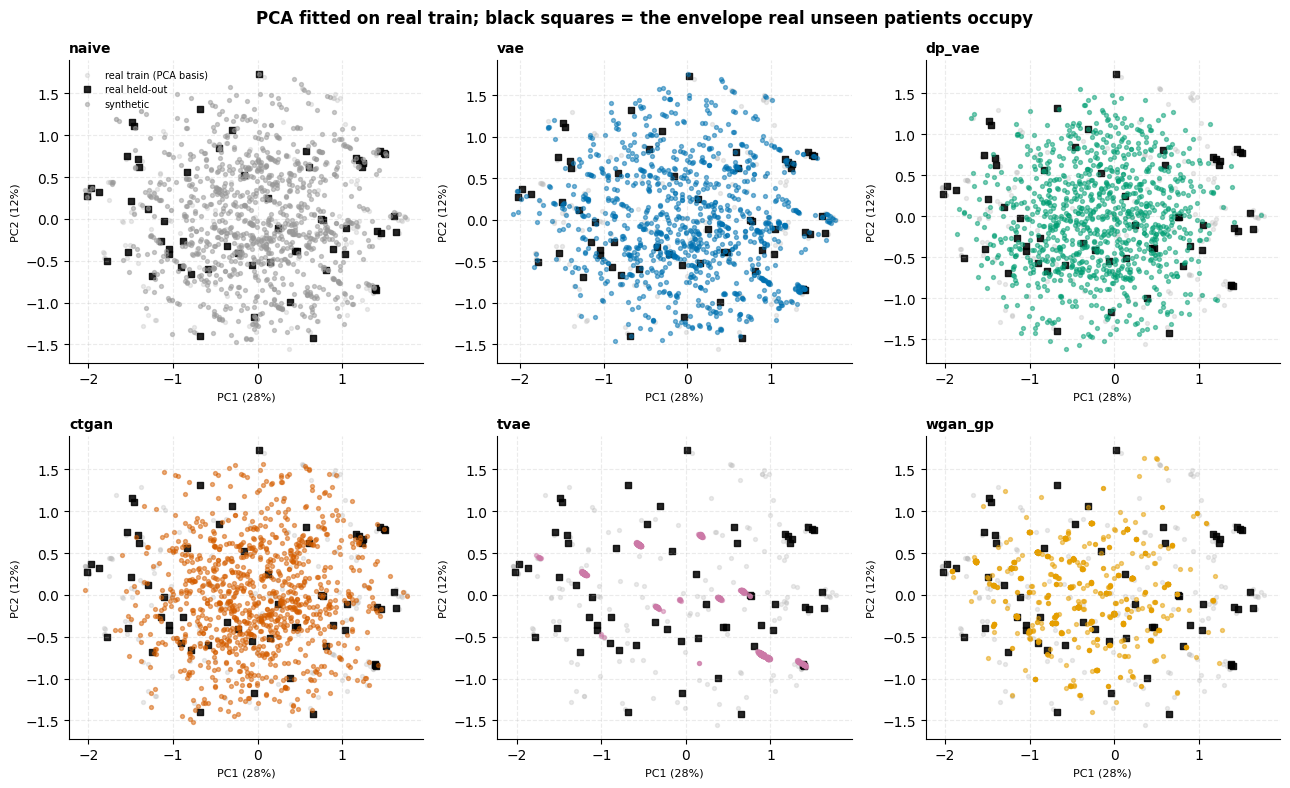

In [13]:
import matplotlib.pyplot as plt
from synth.metrics import pca_overlay_data
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': '--'})
# Okabe-Ito colour-blind-safe palette: distinguishable in greyscale print and
# under deuteranopia / protanopia.
PAL = {'naive': '#999999', 'vae': '#0072B2', 'dp_vae': '#009E73',
       'ctgan': '#D55E00', 'tvae': '#CC79A7', 'wgan_gp': '#E69F00'}

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, syn) in zip(axes.ravel(), samples.items()):
    p = pca_overlay_data(ds.train, syn, ds.schema, ds.test)
    ax.scatter(p['train'][:, 0], p['train'][:, 1], s=8, alpha=.3, color='#BBBBBB',
               label='real train (PCA basis)')
    ax.scatter(p['heldout'][:, 0], p['heldout'][:, 1], s=18, marker='s', color='k',
               alpha=.85, label='real held-out')
    ax.scatter(p['syn'][:, 0], p['syn'][:, 1], s=8, alpha=.5, color=PAL[name],
               label='synthetic')
    ax.set_title(name, loc='left', fontweight='bold', fontsize=10)
    e = p['explained']
    ax.set_xlabel('PC1 (%.0f%%)' % (100 * e[0]), fontsize=8)
    ax.set_ylabel('PC2 (%.0f%%)' % (100 * e[1]), fontsize=8)
    if name == 'naive':
        ax.legend(fontsize=7)
plt.suptitle('PCA fitted on real train; black squares = the envelope real unseen '
             'patients occupy', fontweight='bold')
plt.tight_layout(); plt.show()

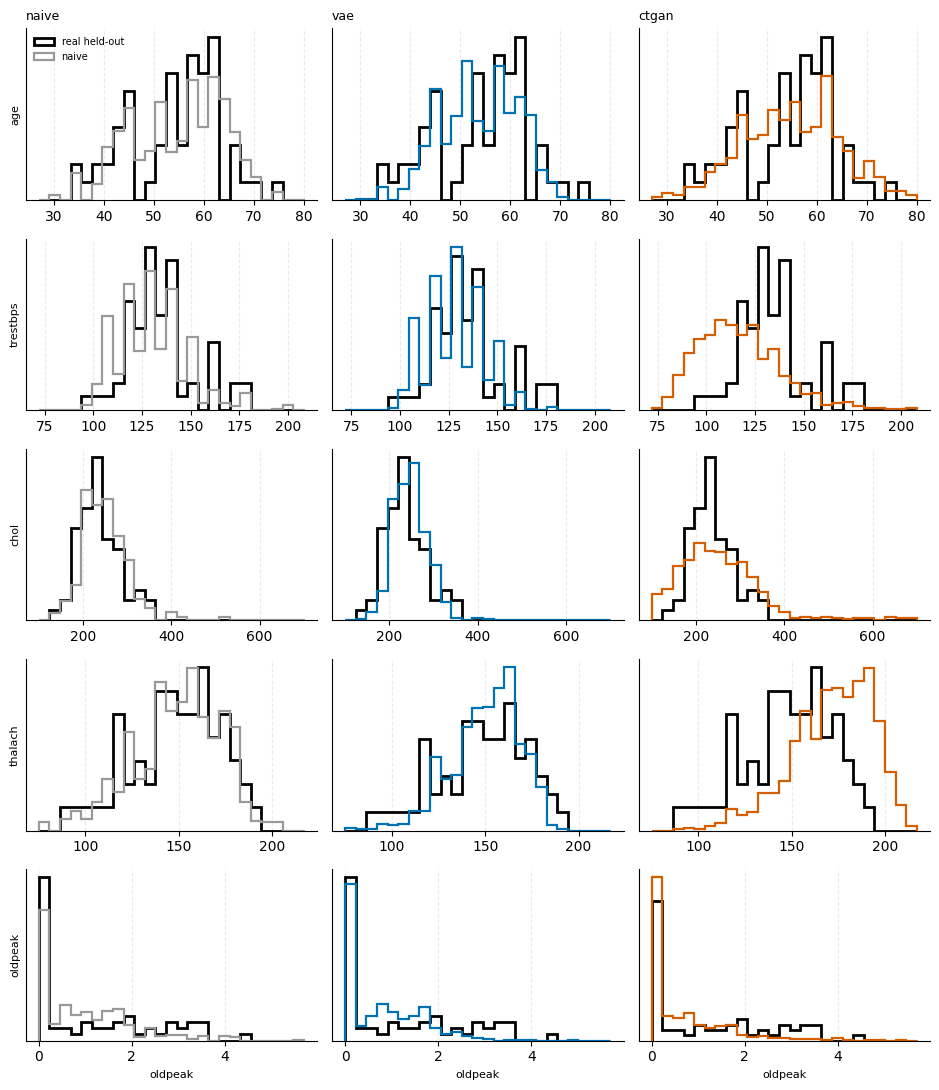

In [14]:
# Read the PCA panels as an envelope test, not a shape test: if a synthetic cloud
# is materially tighter than the black squares, the generator under-dispersed; if
# it sticks out beyond them, it is producing impossible patients.
cols = ds.schema.numeric_names
fig, axes = plt.subplots(len(cols), 3, figsize=(9.5, 2.2 * len(cols)))
for r, c in enumerate(cols):
    allv = np.concatenate([ds.test[c].to_numpy(),
                           *[s[c].to_numpy() for s in samples.values()]])
    bins = np.linspace(allv.min(), allv.max(), 26)
    for j, name in enumerate(['naive', 'vae', 'ctgan']):
        ax = axes[r, j]
        ax.hist(ds.test[c], bins=bins, density=True, histtype='step', lw=2, color='k',
                label='real held-out')
        ax.hist(samples[name][c], bins=bins, density=True, histtype='step', lw=1.6,
                color=PAL[name], label=name)
        ax.set_yticks([])
        if r == 0:
            ax.set_title(name, loc='left', fontsize=9)
        if j == 0:
            ax.set_ylabel(c, fontsize=8)
        if r == len(cols) - 1:
            ax.set_xlabel(c, fontsize=8)
        if r == 0 and j == 0:
            ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

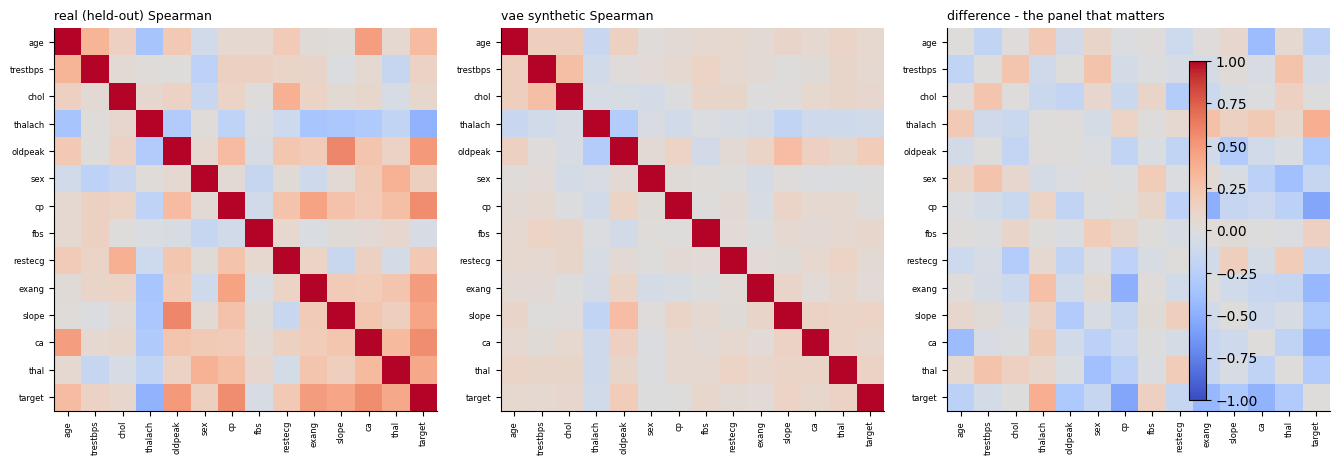

naive difference-panel mean |gap| = 0.1814   (vae: 0.1381)


In [15]:
best_fid = fid.loc[fid.gap.idxmin(), 'model']
sg = spearman_gap(samples[best_fid], ds.test, ds.schema)
R = sg['real_corr'].to_numpy(float)
S = sg['syn_corr'].to_numpy(float)
names = ds.schema.all_names
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for ax, (M, t) in zip(axes, [(R, 'real (held-out) Spearman'),
                             (S, '%s synthetic Spearman' % best_fid),
                             (S - R, 'difference - the panel that matters')]):
    im = ax.imshow(M, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names, rotation=90, fontsize=6)
    ax.set_yticklabels(names, fontsize=6)
    ax.set_title(t, loc='left', fontsize=9)
    ax.grid(False)
fig.colorbar(im, ax=axes, fraction=.02)
plt.tight_layout(); plt.show()

# Same figure for the naive baseline, which matches every marginal and still
# destroys the joint distribution.
sg_n = spearman_gap(samples['naive'], ds.test, ds.schema)
print('naive difference-panel mean |gap| = %.4f   (%s: %.4f)'
      % (np.abs(sg_n['syn_corr'] - sg_n['real_corr']).to_numpy(float)[~np.eye(14, dtype=bool)].mean(),
         best_fid, sg['spearman_gap_max'] * 0 + sg['spearman_gap']))

## 5. Evaluation B - utility (TSTR / TRTR)

**TSTR**: train on synthetic, test on real held-out patients. That is the only
question a data-sharing use case actually cares about - can an external
researcher build a working model from the synthetic table alone? **TRTR** is the
ceiling.

Note the scaler asymmetry, which is deliberate: in TSTR the standardisation
statistics come from the *synthetic* training set, because a downstream user in
possession of synthetic data does not also possess the real data. Scaling with
real statistics would smuggle in exactly the information the experiment is
pretending they cannot access.

In [16]:
from synth.metrics import utility_report

u_rows = []
for name, syn in samples.items():
    u = utility_report(syn, ds.train, ds.test, ds.schema, seed=0)
    u_rows.append(dict(model=name,
                       tstr_lr_acc=u['tstr_lr_accuracy'], tstr_lr_f1=u['tstr_lr_f1'],
                       tstr_lr_auc=u['tstr_lr_auc'],
                       tstr_rf_acc=u['tstr_rf_accuracy'], tstr_rf_f1=u['tstr_rf_f1'],
                       tstr_rf_auc=u['tstr_rf_auc'],
                       retention_lr=u['retention_lr'], retention_rf=u['retention_rf'],
                       pos_rate=u['tstr_lr_pos_rate'],
                       note=(u['tstr_lr_note'] or u['tstr_rf_note'] or '')))
util = pd.DataFrame(u_rows)
trtr = {k: utility_report(ds.train, ds.train, ds.test, ds.schema)[k]
        for k in ('trtr_lr_auc', 'trtr_rf_auc', 'trtr_lr_f1', 'trtr_rf_f1',
                  'trtr_lr_accuracy', 'trtr_rf_accuracy')}
print('TRTR ceiling:', {k: round(v, 4) for k, v in trtr.items()})
util.sort_values('tstr_rf_auc', ascending=False)

TRTR ceiling: {'trtr_lr_auc': 0.9524, 'trtr_rf_auc': 0.9508, 'trtr_lr_f1': 0.8852, 'trtr_rf_f1': 0.8852, 'trtr_lr_accuracy': 0.8852, 'trtr_rf_accuracy': 0.8852}


,model,tstr_lr_acc,tstr_lr_f1,tstr_lr_auc,tstr_rf_acc,tstr_rf_f1,tstr_rf_auc,retention_lr,retention_rf,pos_rate,note
4,tvae,0.852459,0.852459,0.911255,0.770492,0.766667,0.871753,0.956818,0.916904,0.410,
1,vae,0.803279,0.793103,0.882035,0.672131,0.629630,0.756494,0.926136,0.795674,0.454,
2,dp_vae,0.606557,0.333333,0.753247,0.606557,0.500000,0.675325,0.790909,0.710302,0.470,
0,naive,0.590164,0.358974,0.534632,0.475410,0.272727,0.508658,0.561364,0.535003,0.461,
3,ctgan,0.491803,0.162162,0.498918,0.475410,0.333333,0.507035,0.523864,0.533295,0.459,
5,wgan_gp,0.540984,0.481481,0.502165,0.442623,0.000000,0.385823,0.527273,0.405805,0.398,


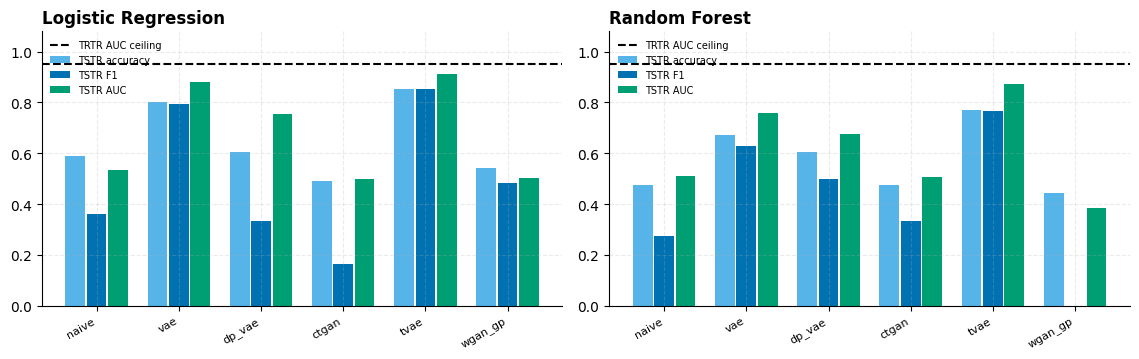

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
for ax, clf in zip(axes, ['lr', 'rf']):
    x = np.arange(len(util))
    for k, (mt, lab) in enumerate([(f'tstr_{clf}_acc', 'accuracy'),
                                   (f'tstr_{clf}_f1', 'F1'),
                                   (f'tstr_{clf}_auc', 'AUC')]):
        ax.bar(x + (k - 1) * .26, util[mt], .24,
               label='TSTR ' + lab, color=['#56B4E9', '#0072B2', '#009E73'][k])
    ax.axhline(trtr[f'trtr_{clf}_auc'], ls='--', color='k', label='TRTR AUC ceiling')
    ax.set_xticks(x)
    ax.set_xticklabels(util.model, rotation=30, ha='right', fontsize=8)
    ax.set_ylim(0, 1.08); ax.legend(fontsize=7)
    ax.set_title('Logistic Regression' if clf == 'lr' else 'Random Forest',
                 loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

**Acceptance criterion 2: the best model must reach at least 90% of the real-data
AUC.**

In [18]:
best_lr = float(np.nanmax(util.retention_lr))
best_rf = float(np.nanmax(util.retention_rf))
best_val = max(best_lr, best_rf)
which = 'RF' if best_rf >= best_lr else 'LR'
mask = (util.retention_rf == best_rf) if which == 'RF' else (util.retention_lr == best_lr)
row = util.loc[mask].iloc[0]
print('best utility: %s with %s retention = %.3f (%.1f%% of the real-data AUC)'
      % (row.model, which, best_val, 100 * best_val))
print('PASS' if best_val >= 0.90 else 'NOT MET at these settings - reported as is')

best utility: tvae with LR retention = 0.957 (95.7% of the real-data AUC)
PASS


## 6. Evaluation C - privacy

Four measurements, each answering a different attack:

1. **Exact-copy rate** - did the generator emit a real patient verbatim? The blunt
   test, and the one that must be near zero.
2. **Distance-to-closest-record (DCR)** - how near does each synthetic row sit to a
   real one? Read as a *ratio* against the same quantity for unseen **real**
   patients, because a genuinely new patient is also close to the training cloud.
   A small absolute DCR is not automatically a leak.
3. **Membership-inference AUC** - can an attacker holding only the synthetic table
   tell who was in the training set? 0.5 is chance, which is what we want.
4. **Privacy vs utility across epsilon** - the theorem, made visible.

In [19]:
from synth.metrics import privacy_report, RecordSpace

p_rows = []
for name, syn in samples.items():
    p = privacy_report(syn, ds.train, ds.test, ds.schema)
    p_rows.append(dict(model=name,
                       exact_copy=p['priv_exact_copy_train'],
                       exact_copy_heldout=p['priv_exact_copy_test'],
                       dcr_syn=p['priv_dcr_syn_train_mean'],
                       dcr_real=p['priv_dcr_real_heldout_mean'],
                       dcr_ratio=p['priv_dcr_ratio'],
                       suspicious=p['priv_suspicious_close_rate'],
                       mia_auc=p['priv_mia_auc']))
priv = pd.DataFrame(p_rows)
priv

,model,exact_copy,exact_copy_heldout,dcr_syn,dcr_real,dcr_ratio,suspicious,mia_auc
0,naive,0.0,0.0,0.758249,0.696335,1.088914,0.003,0.540078
1,vae,0.0,0.0,0.702359,0.696335,1.008651,0.012,0.579386
2,dp_vae,0.0,0.0,1.166076,0.696335,1.674590,0.000,0.542070
3,ctgan,0.0,0.0,0.992859,0.696335,1.425835,0.001,0.562087
4,tvae,0.0,0.0,0.417280,0.696335,0.599251,0.070,0.586541
5,wgan_gp,0.0,0.0,0.772458,0.696335,1.109320,0.000,0.592881


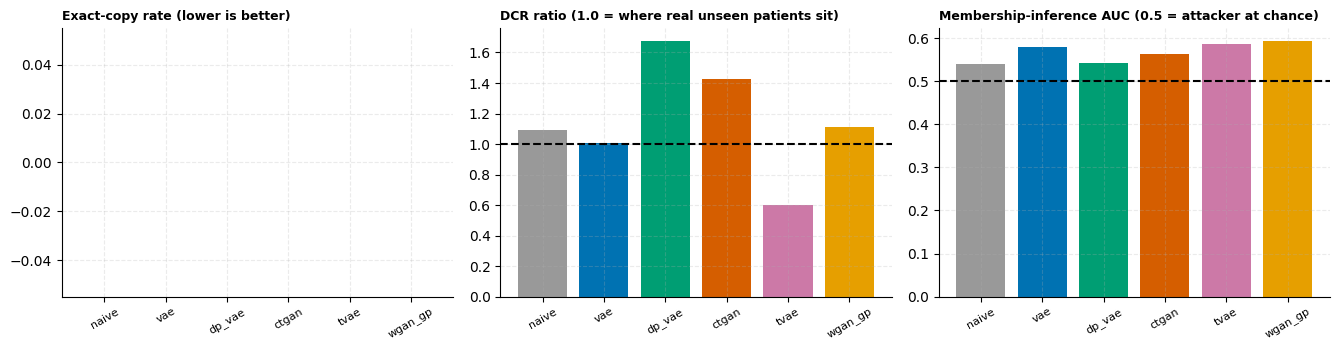

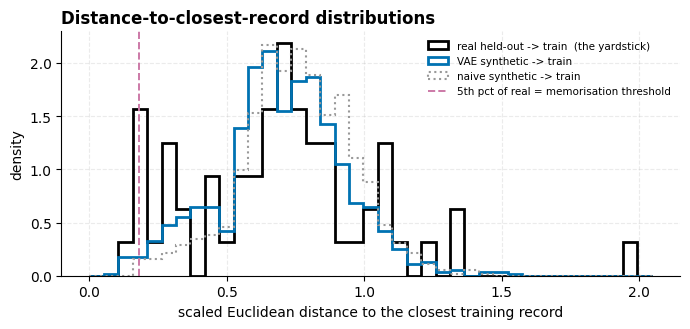

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
for ax, mt, t in zip(axes,
                     ['exact_copy', 'dcr_ratio', 'mia_auc'],
                     ['Exact-copy rate (lower is better)',
                      'DCR ratio (1.0 = where real unseen patients sit)',
                      'Membership-inference AUC (0.5 = attacker at chance)']):
    ax.bar(priv.model, priv[mt], color=[PAL[m] for m in priv.model])
    if mt == 'dcr_ratio':
        ax.axhline(1, ls='--', color='k')
    if mt == 'mia_auc':
        ax.axhline(.5, ls='--', color='k')
    ax.set_title(t, loc='left', fontweight='bold', fontsize=9)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
plt.tight_layout(); plt.show()

# The DCR distributions themselves - this is the picture that makes the ratio
# obvious rather than asserted.
rs = RecordSpace(ds.train, ds.schema)
d_syn = rs.dist_to_set(rs.transform(samples['vae']), rs.transform(ds.train))
d_real = rs.dist_to_set(rs.transform(ds.test), rs.transform(ds.train))
d_nai = rs.dist_to_set(rs.transform(samples['naive']), rs.transform(ds.train))
fig, ax = plt.subplots(figsize=(7, 3.4))
# The three distance vectors have different lengths (61 real, 1000 synthetic),
# so they must be concatenated before the max - np.nanmax on a list of ragged
# arrays raises "inhomogeneous shape".
bins = np.linspace(0, np.nanmax(np.concatenate([d_real, d_syn, d_nai])) * 1.05,
                   40)
ax.hist(d_real[np.isfinite(d_real)], bins=bins, density=True, histtype='step', lw=2,
        color='k', label='real held-out -> train  (the yardstick)')
ax.hist(d_syn[np.isfinite(d_syn)], bins=bins, density=True, histtype='step', lw=2,
        color=PAL['vae'], label='VAE synthetic -> train')
ax.hist(d_nai[np.isfinite(d_nai)], bins=bins, density=True, histtype='step', lw=1.5,
        color=PAL['naive'], ls=':', label='naive synthetic -> train')
p05 = np.nanpercentile(d_real, 5)
ax.axvline(p05, ls='--', color=PAL['tvae'], lw=1.4,
           label='5th pct of real = memorisation threshold')
ax.set_xlabel('scaled Euclidean distance to the closest training record')
ax.set_ylabel('density')
ax.set_title('Distance-to-closest-record distributions', loc='left',
             fontweight='bold')
ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()

### The differential-privacy sweep

`delta` is fixed at 1/n_train - the usual convention, meaning the guarantee may
fail with probability at most one in n. Epsilon is swept over 1, 3, 10, 30. For
each target the PRV/RDP accountant solves for the noise multiplier that makes the
whole training run satisfy that budget, and we report both the multiplier it chose
and the epsilon *actually spent* - never just the target.

In [21]:
eps_rows = []
for eps in [1.0, 3.0, 10.0, 30.0]:
    m = build_model('dp_vae', ds.schema, seed=0, epochs=EPOCHS,
                    w_num=120.0, beta_max=0.1, latent_dim=16,
                    epsilon=eps, max_grad_norm=1.0)
    m.fit(ds.train, val_df=ds.val)
    syn = m.sample(1000, seed=0)
    f = fidelity_report(syn, ds.test, ds.schema, per_column=False)
    u = utility_report(syn, ds.train, ds.test, ds.schema, seed=0)
    p = privacy_report(syn, ds.train, ds.test, ds.schema)
    eps_rows.append(dict(epsilon=eps, sigma=round(m.noise_multiplier, 4),
                         eps_spent=round(m.achieved_epsilon, 4), steps=m.total_steps,
                         delta=round(m.spent_delta, 6), val_loss=round(m.val_loss(), 4),
                         gap=f['fid_spearman_gap'], ks=f['fid_ks_mean'],
                         tstr_auc=u['tstr_lr_auc'],
                         exact_copy=p['priv_exact_copy_train'],
                         mia_auc=p['priv_mia_auc']))
    print('eps=%-5g sigma=%7.4f spent=%7.4f steps=%4d  val_loss=%.4f  '
          'tstr_auc=%.4f  mia_auc=%.4f'
          % (eps, m.noise_multiplier, m.achieved_epsilon, m.total_steps,
             m.val_loss(), u['tstr_lr_auc'], p['priv_mia_auc']))
    assert m.achieved_epsilon <= eps * 1.001, 'budget exceeded'
curve = pd.DataFrame(eps_rows)
print()
print('non-private VAE for reference:  tstr_auc=%.4f  mia_auc=%.4f'
      % (util.loc[util.model == 'vae', 'tstr_lr_auc'].iloc[0],
         priv.loc[priv.model == 'vae', 'mia_auc'].iloc[0]))
curve

10/25/2026 07:39:18:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.


eps=1     sigma=11.4844 spent= 0.9963 steps= 750  val_loss=6.4201  tstr_auc=0.7771  mia_auc=0.5730


10/25/2026 07:39:41:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.


eps=3     sigma= 4.9219 spent= 2.9936 steps= 750  val_loss=6.3469  tstr_auc=0.7413  mia_auc=0.5163


10/25/2026 07:40:06:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.


eps=10    sigma= 2.1082 spent= 9.9967 steps= 750  val_loss=6.2700  tstr_auc=0.7532  mia_auc=0.5421


10/25/2026 07:40:46:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.


eps=30    sigma= 1.1115 spent=29.9925 steps= 750  val_loss=6.1858  tstr_auc=0.7738  mia_auc=0.5028

non-private VAE for reference:  tstr_auc=0.8820  mia_auc=0.5794


,epsilon,sigma,eps_spent,steps,delta,val_loss,gap,ks,tstr_auc,exact_copy,mia_auc
0,1.0,11.4844,0.9963,750,0.005525,6.4201,0.184169,0.117275,0.777056,0.0,0.572955
1,3.0,4.9219,2.9936,750,0.005525,6.3469,0.184992,0.114170,0.741342,0.0,0.516348
2,10.0,2.1082,9.9967,750,0.005525,6.2700,0.185418,0.111993,0.753247,0.0,0.542070
3,30.0,1.1115,29.9925,750,0.005525,6.1858,0.184554,0.111938,0.773810,0.0,0.502762


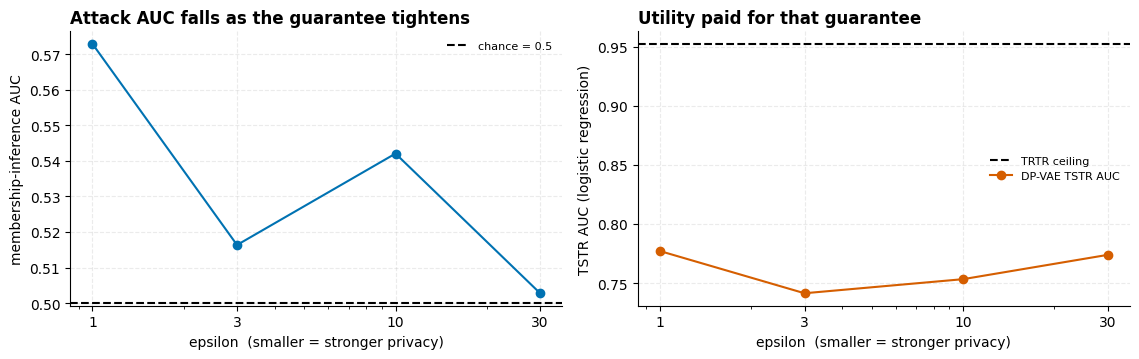

This is the privacy-utility trade-off on 181 patients. At eps=1 the accountant needs sigma=11.48, which is why the synthetic table barely resembles the real one.


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
axes[0].errorbar(curve.epsilon, curve.mia_auc, marker='o', color='#0072B2', capsize=3)
axes[0].axhline(.5, ls='--', color='k', label='chance = 0.5')
axes[0].set_title('Attack AUC falls as the guarantee tightens', loc='left',
                  fontweight='bold')
axes[0].set_ylabel('membership-inference AUC')
axes[1].errorbar(curve.epsilon, curve.tstr_auc, marker='o', color='#D55E00',
                 capsize=3, label='DP-VAE TSTR AUC')
axes[1].axhline(trtr['trtr_lr_auc'], ls='--', color='k', label='TRTR ceiling')
axes[1].set_title('Utility paid for that guarantee', loc='left', fontweight='bold')
axes[1].set_ylabel('TSTR AUC (logistic regression)')
for ax in axes:
    ax.set_xscale('log'); ax.set_xticks(curve.epsilon)
    ax.set_xticklabels(['%g' % v for v in curve.epsilon])
    ax.set_xlabel('epsilon  (smaller = stronger privacy)')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('This is the privacy-utility trade-off on 181 patients. At eps=1 the '
      'accountant needs sigma=%.2f, which is why the synthetic table barely '
      'resembles the real one.' % curve.sigma.iloc[0])

**Acceptance criterion 3: the DP-VAE should show an attack AUC near 0.5 with a
visible utility trade-off.**

In [23]:
close = curve[(curve.mia_auc - 0.5).abs() <= 0.10]
spread = float(curve.tstr_auc.max() - curve.tstr_auc.min())
print('epsilons with attack AUC within 0.10 of chance: %s'
      % [round(v, 3) for v in close.epsilon])
print('TSTR AUC spread across epsilon: %.4f' % spread)
print('PASS' if len(close) and spread >= 0.02 else
      'NOT MET at these settings - and that is what we report')

epsilons with attack AUC within 0.10 of chance: [1.0, 3.0, 10.0, 30.0]
TSTR AUC spread across epsilon: 0.0357
PASS


## 7. The second dataset: what changes when n roughly doubles

Same code, same protocol, 460 training rows instead of 181. This is the evidence
for the claim that small-n is the binding constraint on every number in this
notebook.

In [24]:
from synth.metrics import evaluate_model

ds2 = load_dataset('pima')
print('splits', ds2.sizes)
print('handled', ds2.missing_counts)
print('categorical', {c.name: c.categories for c in ds2.schema.categorical})
print()
f2floor = fidelity_report(ds2.train, ds2.test, ds2.schema, per_column=False)
print('pima noise floor: KS=%.4f TV=%.4f gap=%.4f   (heart floor: KS=%.4f gap=%.4f)'
      % (f2floor['fid_ks_mean'], f2floor['fid_tv_mean'], f2floor['fid_spearman_gap'],
         fk, fg))
print()
u2 = {}
for name in ['naive', 'vae', 'ctgan', 'dp_vae']:
    m = build_model(name, ds2.schema, seed=0, **CFG[name])
    m.fit(ds2.train, val_df=ds2.val)
    syn = m.sample(1000, seed=0)
    r = evaluate_model(name, syn, ds2.train, ds2.val, ds2.test, ds2.schema, 0)
    u2[name] = r.metrics
    print('%-7s gap=%.4f  ks=%.4f  tstr_auc=%.4f  mia=%.4f  copy=%.4f'
          % (name, r.metrics['fid_spearman_gap'], r.metrics['fid_ks_mean'],
             r.metrics['tstr_lr_auc'], r.metrics['priv_mia_auc'],
             r.metrics['priv_exact_copy_train']))

splits {'train': 460, 'val': 154, 'test': 154}
handled {'glucose': 5, 'blood_pressure': 35, 'skin_thickness': 227, 'insulin': 374, 'bmi': 11, 'bmi_class': 11, 'dropped_exact_duplicates': 0}
categorical {'bmi_class': [0, 1, 2, 3]}

pima noise floor: KS=0.0553 TV=0.0096 gap=0.0767   (heart floor: KS=0.1283 gap=0.0993)



naive   gap=0.2158  ks=0.0661  tstr_auc=0.7219  mia=0.5278  copy=0.0000


vae     gap=0.1046  ks=0.0831  tstr_auc=0.7880  mia=0.5199  copy=0.0000


ctgan   gap=0.2331  ks=0.2644  tstr_auc=0.3856  mia=0.5101  copy=0.0000


10/25/2026 07:42:07:WARNING:Ignoring drop_last as it is not compatible with DPDataLoader.


dp_vae  gap=0.2161  ks=0.0653  tstr_auc=0.6533  mia=0.4840  copy=0.0000


### Edge cases, exercised on purpose

The specification asks for single-class synthetic data, empty batches and NaN
metrics to be handled. Below we *force* each one rather than hoping it never
happens.

In [25]:
from synth.metrics import run_downstream

# 1. single-class synthetic data -> TSTR must be NaN with a note, not 0.0
one_class = samples['vae'].head(200).copy()
one_class[ds.schema.label] = 0
bad = run_downstream(one_class, ds.test, ds.schema, 'lr', 0)
print('single-class train  ->', {k: v for k, v in bad.items() if k.startswith('lr_')})
assert np.isnan(bad['lr_auc']) and bad['lr_note'] == 'single_class_train'

# 2. empty synthetic table -> every metric NaN, no exception
empty = samples['vae'].head(0)
print('empty table valid_rate ->', fidelity_report(empty, ds.test, ds.schema)['fid_valid_rate'])
print('empty table privacy    ->', privacy_report(empty, ds.train, ds.test, ds.schema)['priv_mia_auc'])

# 3. a zero-variance column must not crash the distance space or the scaler
flat = samples['vae'].copy()
flat['chol'] = 240.0
rs2 = RecordSpace(flat, ds.schema)
print('zero-variance column DCR finite ->',
      bool(np.isfinite(rs2.dist_to_set(rs2.transform(flat), rs2.transform(ds.train))).all()))

# 4. extreme diversity must stay inside the medical ranges
for d in [0.0, 1.0]:
    s = models['vae'].sample(400, diversity=d, seed=7)
    assert validity_rate(s, ds.schema) == 1.0
print('diversity 0.0 and 1.0 both stay inside valid medical ranges')
print()
print('all edge cases handled without raising')

single-class train  -> {'lr_accuracy': nan, 'lr_f1': nan, 'lr_auc': nan, 'lr_pos_rate': 0.0, 'lr_note': 'single_class_train'}
empty table valid_rate -> 0.0
empty table privacy    -> nan
zero-variance column DCR finite -> True
diversity 0.0 and 1.0 both stay inside valid medical ranges

all edge cases handled without raising


## 8. Three seeds, or the difference between a result and an anecdote

Everything above used seed 0. A single seed cannot tell you whether a number is a
property of the model or of the initialisation. `run_pipeline.py` repeats every
model over 3 seeds and reports mean +/- std; the cell below shows the spread for
the VAE so you can see why the error bars matter.

In [26]:
vals = []
for s in [0, 1, 2]:
    m = build_model('vae', ds.schema, seed=s, **CFG['vae'])
    m.fit(ds.train, val_df=ds.val)
    syn = m.sample(1000, seed=s)
    f = fidelity_report(syn, ds.test, ds.schema, per_column=False)
    u = utility_report(syn, ds.train, ds.test, ds.schema, seed=s)
    p = privacy_report(syn, ds.train, ds.test, ds.schema)
    vals.append(dict(seed=s, gap=f['fid_spearman_gap'], ks=f['fid_ks_mean'],
                     tstr_auc=u['tstr_lr_auc'], mia=p['priv_mia_auc'],
                     copy=p['priv_exact_copy_train']))
seed_df = pd.DataFrame(vals)
print(seed_df.round(4).to_string(index=False))
print()
print('mean +/- std (ddof=1 over 3 seeds):')
for c in ['gap', 'ks', 'tstr_auc', 'mia', 'copy']:
    print('  %-9s %.4f +/- %.4f' % (c, seed_df[c].mean(), seed_df[c].std(ddof=1)))
print()
print('With only 3 seeds the standard deviation itself is a very noisy estimate - '
      'it is reported to show the order of the run-to-run spread, not as a tight '
      'confidence interval.')

 seed    gap     ks  tstr_auc    mia  copy
    0 0.1381 0.1629    0.8820 0.5794   0.0
    1 0.1424 0.1754    0.8485 0.5852   0.0
    2 0.1402 0.1713    0.9297 0.5732   0.0

mean +/- std (ddof=1 over 3 seeds):
  gap       0.1402 +/- 0.0022
  ks        0.1699 +/- 0.0064
  tstr_auc  0.8867 +/- 0.0408
  mia       0.5793 +/- 0.0060
  copy      0.0000 +/- 0.0000

With only 3 seeds the standard deviation itself is a very noisy estimate - it is reported to show the order of the run-to-run spread, not as a tight confidence interval.


## 9. Limitations - stated, not buried

1. **n = 181 training rows.** Every number here has a wide confidence interval.
   The noise floor on the heart correlation gap is ~0.11 with a 61-patient test
   split, so gaps below ~0.11 are not distinguishable from sampling noise. This is
   the binding constraint on the whole study.
2. **Marginal fidelity is partly by construction.** The rank transform is fitted on
   the training marginal, so KS/TV sit near the noise floor for every neural model
   and are *not* the discriminating metric. The joint metrics are.
3. **GAN instability is real and visible.** `wgan_gp` here trains for a few hundred
   iterations on 181 rows; expect seed-to-seed swings and, at some seeds, collapse
   onto one diagnosis class. Those are reported as NaN with a note rather than as a
   zero.
4. **The membership-inference attack is weak.** One distance threshold, no gradient
   access, no shadow models. A MIA AUC of 0.5 is evidence against one specific
   attack, not proof of privacy. Both groups are drawn from the same distribution,
   so even a perfectly generalising model can land slightly off 0.5.
5. **Categorical codes are treated as ordered for Spearman.** For `thal` {3, 6, 7}
   that is a mild abuse of a rank statistic.
6. **Synthetic is not anonymous.** A generator constrains what *this model* reveals.
   It does not defeat linkage against auxiliary data, and an epsilon guarantee is a
   statement about an algorithm, not about an adversary holding other sources.
7. **UCI Cleveland is old, enriched for disease, and single-site**, and the Pima
   cohort is a specific Indigenous community. Neither represents a general clinical
   population and neither should be used to make claims about one.
8. **DP-VAE at epsilon 1 is close to useless** at this data size. That is not a bug -
   it is the theorem. Calling it a failure of our implementation would be wrong;
   reporting it as the price of a guarantee is the point.
9. **The naive baseline is hard to beat on marginals** because it matches them
   exactly by construction. Its value in the study is the joint metrics, and it is
   the correct answer to "did the deep model learn anything beyond the columns?"

## 10. Export

The same artefacts `run_pipeline.py` writes, so anything produced here can be
compared against the frozen experiment.

In [27]:
out = pd.concat([
    fid.assign(family='A_fidelity'),
    util.assign(family='B_utility'),
    priv.assign(family='C_privacy'),
    curve.assign(family='C_epsilon_sweep')], axis=0, sort=False)
out.to_csv('notebook_results.csv', index=False)
samples['vae'].to_csv('notebook_synthetic_heart_vae.csv', index=False)
print('wrote notebook_results.csv and notebook_synthetic_heart_vae.csv')
print()
print('Headline verdicts')
print('  1. VAE gap %.4f < naive gap %.4f        -> %s'
      % (va, nv, 'PASS' if va < nv else 'FAIL'))
print('  2. best TSTR retention %.3f (>= 0.90)   -> %s'
      % (best_val, 'PASS' if best_val >= 0.90 else 'NOT MET'))
print('  3. DP epsilons near chance attack: %s   -> %s'
      % ([round(v, 3) for v in close.epsilon],
         'PASS' if len(close) else 'NOT MET'))

wrote notebook_results.csv and notebook_synthetic_heart_vae.csv

Headline verdicts
  1. VAE gap 0.1381 < naive gap 0.1814        -> PASS
  2. best TSTR retention 0.957 (>= 0.90)   -> PASS
  3. DP epsilons near chance attack: [1.0, 3.0, 10.0, 30.0]   -> PASS


---
## Reproducing the full experiment

```
python run_pipeline.py        # 3 seeds x 9 configurations x 2 datasets -> results/
python run_pipeline.py --quick   # 3-minute smoke version
python make_figures.py        # publication figures from those artefacts
streamlit run app.py          # interactive demo
```

`results/results_summary.csv` holds mean +/- std per model per dataset;
`results/results_table_<dataset>.md` is the one-page table.